In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from model import ExponentialRepresentation
from utils import plot_ratemaps, rectify, construct_exponential, batch_inference, orthogonal_basis

In [2]:
# init R 
# R is a basis for the plane sum_i p_i = 0

In [3]:
sA = torch.load("sigma_A.pt", weights_only=True) # Must run fourier_approximation.ipynb first now!
sB = torch.load("sigma_B.pt", weights_only=True)

A, B, _ = construct_exponential(sA, sB, sB*0, s = 0) 

N = len(A)

In [4]:
one_vec = np.ones(N + 1)/np.sqrt(N + 1)

# Step 2: Create R ∈ R^{(n-1) × n}, with rowspace orthogonal to 1
# This is done by orthonormalizing a basis of the orthogonal complement of 1
# Step 2: Perform Gram-Schmidt starting from the ones vector

# Now R is the projection matrix onto the plane orthogonal to 1
R = torch.tensor(orthogonal_basis(one_vec).astype("float32"))
R = R[1:] # remove ones vector from basis!
R.shape

torch.Size([512, 513])

In [5]:
signs = torch.tensor([(-1)**i for i in range(N)]).float()

# p0 should be in the zero-sum plane
p0 = R.T@signs 
p0 = p0/torch.linalg.norm(p0)
p0.shape

torch.Size([513])

In [6]:
model = ExponentialRepresentation(R.T@A@R, R.T@B@R)

/home/m/Documents/phd/ESR/model.py:20: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A = torch.tensor(A, device=self.device, requires_grad=False)
/home/m/Documents/phd/ESR/model.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.B = torch.tensor(B, device=self.device, requires_grad=False)


In [7]:
batch_size = 50 # number of spatial samples
batches = 500
arena_size = 10
r_batch = [arena_size*(2*torch.rand((batch_size, 2)).to(torch.float32) - 1) for i in range(batches)]

p = batch_inference(model, r_batch, p0)
z = p + np.ones((1, N+1)) # avoid numerical issues
r = np.concatenate(r_batch)

100%|██████████| 500/500 [00:38<00:00, 12.88it/s]


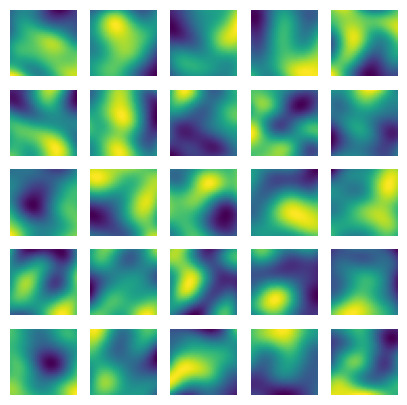

In [8]:
ratemaps = plot_ratemaps(r[:,0], r[:,1], z, 5, figsize=(5,5), bins = 32)

In [9]:
norm = np.linalg.norm(ratemaps, axis=0)
rate_sum = np.sum(ratemaps, axis=0)

Text(0.5, 1.0, 'Histogram of (shifted) rates')

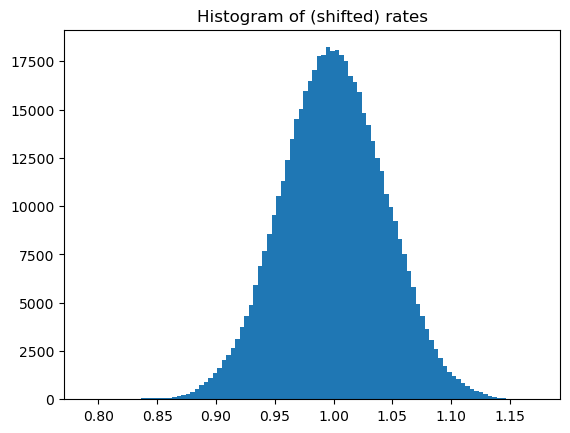

In [10]:
plt.hist(ratemaps.ravel(), bins = 100)
plt.title("Histogram of (shifted) rates")

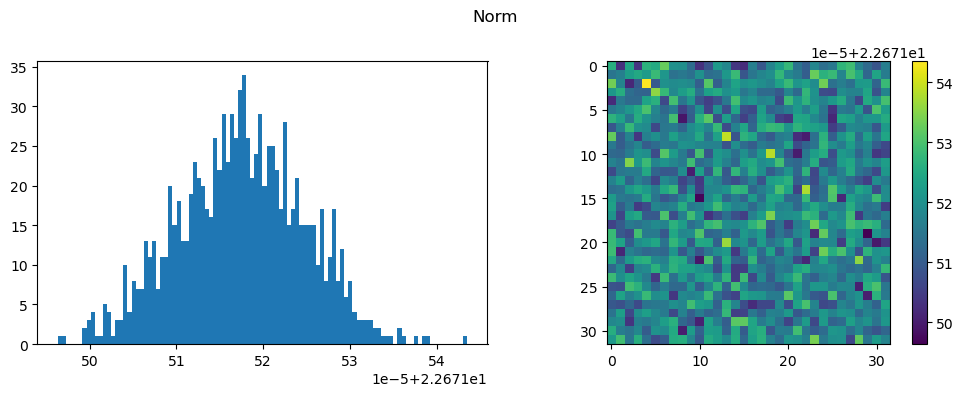

In [11]:
fig, ax = plt.subplots(1, 2, figsize = (10, 4))

ax[0].hist(norm.ravel(), bins = 100)
im = ax[1].imshow(norm)
fig.suptitle("Norm")
plt.colorbar(im, ax = ax[1] )
plt.tight_layout()

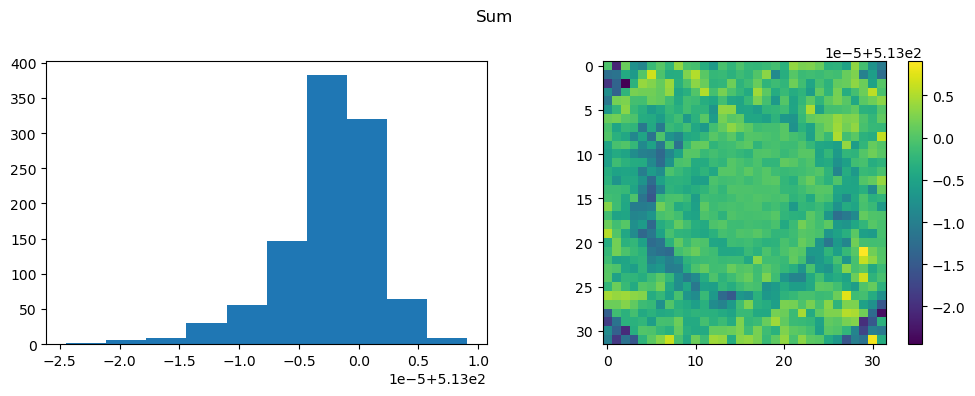

In [12]:
fig, ax = plt.subplots(1, 2, figsize = (10, 4))

ax[0].hist(rate_sum.ravel(), bins = 10)

im = ax[1].imshow(rate_sum)
fig.suptitle("Sum")
plt.colorbar(im, ax = ax[1])
plt.tight_layout()

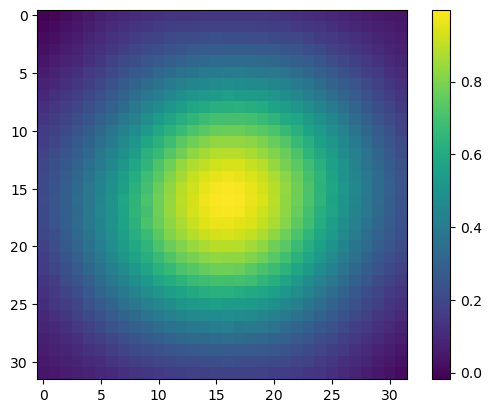

In [18]:
a = 16
corr = np.sum(ratemaps[:, a, a, None, None]*ratemaps, axis = 0)
plt.imshow(corr.T - (N + 1))
plt.colorbar()